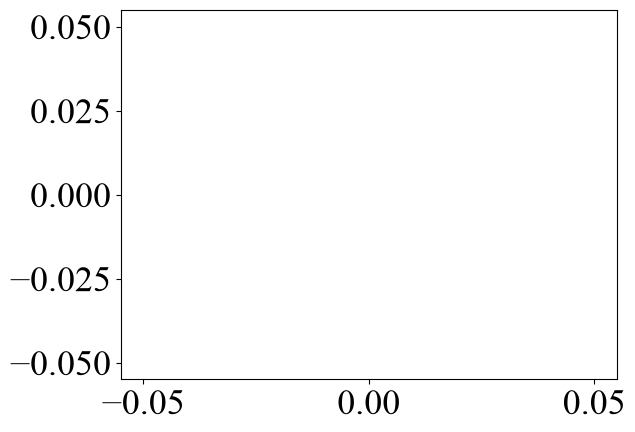

In [9]:
# This notebook creates the pltos and stats required for the Operator Math paper

import glob, os, warnings
import numpy as np
import pandas as pd
import scipy
from scipy import optimize, stats
from scipy.stats import norm
import copy
import warnings

import aplpy
#import healpy as hp
import matplotlib as mpl
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pylab as pl
#import seaborn as sns

from colormaps import spectral
from matplotlib.patches import Circle
from matplotlib import colors
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import ColorConverter, SymLogNorm, Normalize
from matplotlib.ticker import (
    FuncFormatter, LogFormatterMathtext, ScalarFormatter,
    SymmetricalLogLocator,
)
from matplotlib.ticker import StrMethodFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import astropy.units as u
from astropy.coordinates import EarthLocation, SkyCoord
from astropy.cosmology import LambdaCDM
from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.table import Table
from astropy.time import Time
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_area, proj_plane_pixel_scales
from astropy.wcs.wcs import FITSFixedWarning
#from reproject import reproject_from_healpix

from abc import ABC, abstractmethod
from pathlib import Path
from typing import Any, Self

import attrs
import cattrs
import numpy as np
import pandas as pd
import yaml
from attrs.converters import optional as optconv

warnings.filterwarnings("ignore", category=FITSFixedWarning)

init_dir = '/Users/nicholebarry/OneDrive - UNSW/'
#init_dir = '/Users/z3543600/OneDrive - UNSW/'

# ---------------------------------------------------------------------
# Plot configuration

times_font = True

if times_font:
    font_name = "Times"
    font_bold = fm.FontProperties(family="Times New Roman", size=32, weight="bold")
    font = fm.FontProperties(family="Times", size=14)
    # plt.rcParams.update({
    #     "text.usetex": True, "font.family": "Times New Roman",
    #     "mathtext.fontset": "stix", "axes.unicode_minus": False,
    #     "text.latex.preamble": r"\usepackage{newtxtext,newtxmath}",
    # })
    mpl.rcParams.update({
        "text.usetex": False,
        "font.family": "Times New Roman",
        "mathtext.fontset": "custom",
        "mathtext.rm": "Times New Roman",
        "mathtext.it": "Times New Roman:italic",
        "mathtext.bf": "Times New Roman:bold",
        "axes.unicode_minus": True,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })
else:
    font_name = "DejaVu Sans"
    font_bold = fm.FontProperties(family=font_name, size=14, weight="bold")
    font = fm.FontProperties(family=font_name, size=14)

mpl.rc("font", size=26)
mpl.rc("axes", labelsize=26)

# cb_spec, cb_spec_r = spectral()
# cb_spec.set_bad("white")
# cb_spec = plt.get_cmap("BuPu").copy()
# cb_spec.set_bad("white")
from matplotlib.colors import LinearSegmentedColormap

# cb_spec = LinearSegmentedColormap.from_list(
#     "publication_purples",
#     [
#         #(0.00, "#f2f0f7"),  # 2016
#         (0.00, "#eee8f4"),
#         (0.20, "#dadaeb"),  # 2018
#         (0.30, "#bcbddc"),  # 2019
#         (0.35, "#9e9ac8"),  # between 2019 and 2020
#         (0.40, "#807dba"),  # 2020
#         (0.60, "#6a51a3"),  # 2022
#         (0.80, "#54278f"),  # 2024
#         (1.00, "#1b0033"),  # 2026
#     ],
# )
cb_spec = LinearSegmentedColormap.from_list(
    "publication_purples",
    [
        (0.00, "#eee8f4"),  # 2016
        (0.20, "#dadaeb"),  # 2018
        (0.30, "#c0a2d0"),  # 2019
        (0.40, "#8c62b5"),  # 2020
        (0.50, "#613f99"),  # 2021
        (0.60, "#4a1486"),  # 2022
        (0.80, "#3b0f70"),  # 2024
        (1.00, "#1b0033"),  # 2026
    ],
)


def _colourbar_scale(vmin, vmax):
    """Create an invisible mappable for a shared colour-bar scale."""
    return plt.pcolor(
        [0, 0], [0, 0], [[0, 0], [0, 0]],
        norm=colors.Normalize(vmin=vmin, vmax=vmax), cmap=cb_spec,
    )


colorbar_scale_catalog = _colourbar_scale(0, 6000)
colorbar_scale_nobeam = _colourbar_scale(-6000, 6000)
colorbar_scale_inst = _colourbar_scale(-50, 50)
colorbar_scale_data = _colourbar_scale(-100, 100)

ColorConverter.colors.update({
    "e": (94 / 256, 79 / 256, 162 / 256),
    "g": (50 / 256, 136 / 256, 189 / 256),
    "h": (102 / 256, 194 / 256, 165 / 256),
    "i": (253 / 256, 174 / 256, 97 / 256),
    "j": (219 / 256, 55 / 256, 82 / 256),
})


def deg_formatter(x, pos):
    """Format an axis value as degrees."""
    return rf"${x:.1f}^\circ$"



In [2]:
"""Standalone dataset types, limit YAML loaders, and Python theory registry."""

from abc import ABC, abstractmethod
from collections.abc import Iterable
import hashlib
import importlib.util
from pathlib import Path
import sys
import types
from typing import Any, Self

import attrs
import cattrs
import numpy as np
import pandas as pd
import yaml
from attrs.converters import optional as optconv

converter = cattrs.Converter(use_alias=True)


@converter.register_structure_hook
def _make_array(x: Any, _) -> np.ndarray:
    return np.asarray(x, dtype=float)


def _floatarray(x):
    return np.array(x, dtype=float)


def _tuple_of_floatarrays(x):
    return tuple(np.array(arr, dtype=float) for arr in x)


@attrs.define(frozen=True, kw_only=True)
class Data:
    r"""
    Class representing the data for a single dataset.

    The data consists of arrays of redshift values |z|, |k| values
    for those redshifts, and the corresponding power spectrum upper limits
    |dsq|, along with optional lower and upper bounds
    on the |z| and |k| values.

    Attributes
    ----------
    z : np.ndarray
        A 1D array of redshift values |z| for the dataset.
    z_lower : np.ndarray | None
        A 1D array of lower bounds on the |z|-bins,
        or ``None`` if not available.
    z_upper : np.ndarray | None
        A 1D array of upper bounds on the |z|-bins,
        or ``None`` if not available.
    z_tags : tuple[str, ...] | None
        A 1D array of tags for the |z| values (e.g. ``'Pol E-W'``, ``'Field 1'``),
        or ``None`` if not available. Thus, different polarizations or fields
        are treated as separate redshift entries with the same k value
        but different tags.
    k : tuple[np.ndarray, ...]
        A tuple of 1D arrays of scale values |k|, one for each redshift value,
        in units of |h/Mpc|.
    k_lower : tuple[np.ndarray, ...] | None
        A tuple of 1D arrays of lower bounds on the |k|-bins, one for each
        redshift value, in units of |h/Mpc|, or ``None`` if not available.
    k_upper : tuple[np.ndarray, ...] | None
        A tuple of 1D arrays of upper bounds on the |k|-bins, one for each
        redshift value, in units of |h/Mpc|, or ``None`` if not available.
    delta_squared : tuple[np.ndarray, ...]
        A tuple of 1D arrays of |dsq| values, one for each
        redshift value, in units of |mK^2|.
    """

    z: np.ndarray = attrs.field(converter=_floatarray)
    z_lower: np.ndarray | None = attrs.field(default=None, converter=optconv(_floatarray))
    z_upper: np.ndarray | None = attrs.field(default=None, converter=optconv(_floatarray))
    z_tags: tuple[str, ...] | None = attrs.field(default=None)

    k: tuple[np.ndarray, ...] = attrs.field(converter=_tuple_of_floatarrays)
    k_lower: tuple[np.ndarray, ...] | None = attrs.field(default=None, converter=optconv(_tuple_of_floatarrays))
    k_upper: tuple[np.ndarray, ...] | None = attrs.field(default=None, converter=optconv(_tuple_of_floatarrays))

    _delta: tuple[np.ndarray, ...] | None = attrs.field(default=None)
    _delta_squared: tuple[np.ndarray, ...] | None = attrs.field(default=None)

    def __repr__(self) -> str:
        """Return a string representation of Data, as a pandas DataFrame."""
        return self.as_pandas_df().__repr__()

    @z.validator
    def _check_z(self, attribute, value):
        if len(value) == 0:
            raise ValueError("z cannot be empty.")
        if not (value > 0).all():
            raise ValueError("All z values must be positive.")

    @z_lower.validator
    @z_upper.validator
    def _check_z_bounds(self, attribute, value):
        if value is not None:
            if not (value > 0).all():
                raise ValueError(f"All {attribute.name} values must be positive.")
            if not value.shape == self.z.shape:
                raise ValueError(f"{attribute.name} must be the same shape as z.")

    @z_lower.validator
    def _check_z_lower(self, attribute, value):
        if value is not None and (value > self.z).any():
            raise ValueError("All z_lower values must be less than or equal to z.")

    @z_upper.validator
    def _check_z_upper(self, attribute, value):
        if value is not None and (value < self.z).any():
            raise ValueError("All z_upper values must be greater than or equal to z.")

    @z_tags.validator
    def _check_z_tags(self, attribute, value):
        if value is not None:
            if not all(isinstance(x, str) for x in value):
                raise ValueError("z_tags must be a 1D array of strings.")
            if len(value) != self.z.shape[0]:
                raise ValueError("z_tags must be the same shape as z.")

    @k.validator
    def _check_k(self, attribute, value):
        if len(value) != len(self.z):
            raise ValueError("k must have the same number of entries as z.")
        for arr in value:
            if not (arr > 0).all():
                raise ValueError("All k values must be positive.")

    @k_upper.validator
    @k_lower.validator
    @_delta.validator
    @_delta_squared.validator
    def _check_k_bounds(self, attribute, value):
        if value is not None:
            if len(value) != len(self.z):
                raise ValueError(f"{attribute.name} must have the same number of entries as z.")
            for kk, arr in zip(self.k, value, strict=True):
                if not arr.shape == kk.shape:
                    raise ValueError(f"{attribute.name} must have the same shape as k.")

                if arr.dtype != float:
                    raise ValueError(
                        f"{attribute.name} must be an array of floats. "
                        f"Got {arr.dtype} instead -- check the YAML formatting."
                    )
                if not (arr[np.isfinite(arr)] >= 0).all():
                    raise ValueError(f"All {attribute.name} values must be positive.")

    @k_upper.validator
    def _check_k_upper(self, attribute, value):
        if value is not None:
            for kk, arr in zip(self.k, value, strict=True):
                if (arr < kk).any():
                    raise ValueError("All k_upper values must be greater than or equal to k.")

    @k_lower.validator
    def _check_k_lower(self, attribute, value):
        if value is not None:
            for kk, arr in zip(self.k, value, strict=True):
                if (arr > kk).any():
                    raise ValueError("All k_lower values must be less than or equal to k.")

    @_delta_squared.validator
    def _check_delta_squared(self, attribute, value):
        if value is None and self._delta is None:
            raise ValueError("Either delta_squared or delta must be provided.")
        if value is not None and self._delta is not None:
            raise ValueError("Only one of delta_squared or delta can be provided.")

    @property
    def delta_squared(self) -> tuple[np.ndarray, ...]:
        if self._delta_squared is not None:
            return tuple(np.asarray(arr) for arr in self._delta_squared)
        if self._delta is not None:
            return tuple(np.asarray(arr) ** 2 for arr in self._delta)
        raise ValueError("Either delta_squared or delta must be provided.")

    def as_pandas_df(self) -> pd.DataFrame:
        """
        Convert the Data object to a pandas DataFrame.

        This is useful for viewing the data in a tabular format
        or using the slicing/conversion capabilities of pandas.
        """
        # Create DataFrame row by row for each z value
        rows = []
        for i in range(len(self.z)):
            row = {
                "z": self.z[i],
                "z_lower": self.z_lower[i] if self.z_lower is not None else None,
                "z_upper": self.z_upper[i] if self.z_upper is not None else None,
                "z_tags": self.z_tags[i] if self.z_tags is not None else "",
                "k": np.array(self.k[i]),
                "k_lower": np.array(self.k_lower[i])
                if self.k_lower is not None
                else None,
                "k_upper": np.array(self.k_upper[i])
                if self.k_upper is not None
                else None,
                "delta_squared": np.array(self.delta_squared[i]),
            }
            rows.append(row)
        return pd.DataFrame(rows)

    def drop_nan(self) -> Self:
        """
        Return a new Data object with any rows containing NaN values removed.

        Returns
        -------
        Data
            A new Data object containing only the data points with no NaN values in
            |z|, |k| or |dsq|.
        """

        def mask(dsq):
            return np.isfinite(dsq)

        return attrs.evolve(
            self,
            k=tuple(kk[mask(dsq)] for kk, dsq in zip(self.k, self.delta_squared, strict=True)),
            k_lower=tuple(kl[mask(dsq)] for kl, dsq in zip(self.k_lower, self.delta_squared, strict=True))
            if self.k_lower is not None
            else None,
            k_upper=tuple(ku[mask(dsq)] for ku, dsq in zip(self.k_upper, self.delta_squared, strict=True))
            if self.k_upper is not None
            else None,
            delta_squared=tuple(dsq[mask(dsq)] for dsq in self.delta_squared),
            delta=None,
        )


@attrs.define(frozen=True)
class DataSet:
    r"""
    Class representing a dataset, including metadata and the data itself.

    The metadata includes the telescope, author, year and DOI of the dataset,
    as well as any additional notes. The data is stored in a ``Data`` object,
    which contains arrays of redshifts |z|, scales |k| (in units of
    |h/Mpc|) and |dsq| (in units of |mK^2|).

    Attributes
    ----------
    telescope : str
        The name of the telescope or experiment that produced the dataset.
    author : str
        The name of the first author of the dataset,
        or the collaboration name if applicable.
    year : int
        The year the dataset was published.
    doi : str
        The DOI of the dataset. Only published datasets with DOIs should be
        included in the repository.
    data : Data
        The data for the dataset, stored in a Data object.
    notes : tuple[str, ...]
        Any additional notes about the dataset, such as details of the analysis
        or assumptions made about k-bins.
    key : str
        A unique key for the dataset, automatically generated from the author and
        year (e.g. ``'Paciga2013'``). This is used for referencing the dataset.
    """

    telescope: str = attrs.field(converter=str)
    author: str = attrs.field(converter=str)
    year: int = attrs.field(converter=int)
    doi: str = attrs.field(converter=str)
    data: Data = attrs.field(validator=attrs.validators.instance_of(Data))
    month: int | None = attrs.field(default=None,converter=optconv(int),validator=attrs.validators.optional(attrs.validators.in_(range(1, 13))),)
    notes: tuple[str, ...] = attrs.field(default=(), validator=attrs.validators.instance_of(tuple))
    _key: str = attrs.field(converter=str)

    @_key.default
    def _default_key(self) -> str:
        """Generate a default key based on the author and year."""
        return f"{self.author}{self.year}"

    def __repr__(self) -> str:
        """Return a string representation of the DataSet, including metadata."""
        string = "DataSet(\n"
        string += f"\t telescope='{self.telescope}',\n"
        string += f"\t author='{self.author}',\n"
        string += f"\t year={self.year},\n"
        string += f"\t doi='{self.doi}',\n"
        if self.notes:
            string += f"\t notes={self.notes},\n"
        string += "\t data=\n\t\t"
        string_data = self.data.__repr__().replace("\n", "\n\t\t")
        string += string_data
        string += "\n)"
        return string

    @classmethod
    def load(cls, path: str | Path, /, *, base_dir: str | Path | None = None) -> Self:
        """
        Load a DataSet from a YAML file.

        ``path`` can be an absolute path, a relative path, or a filename relative to
        ``base_dir``. A ``.yaml`` suffix is added when the path has no suffix.

        The YAML file must be formatted correctly with the required fields for metadata
        and data, as shown below.

        .. code-block:: yaml

            telescope: GMRT
            author: Paciga
            year: 2013
            doi: 10.1093/mnras/stt753
            data:
              delta_squared: [[6.15e4]]
              k: [[0.5]]
              z: [8.6]

        The limits can be provided as either ``delta`` (|delta|) or
        ``delta_squared`` (|dsq|), but not both.
        If |delta| is provided, it will be squared to obtain |dsq|.
        The |k| values must be provided in units of |h/Mpc|.

        Parameters
        ----------
        path : str | Path
            The path or filename of the YAML file containing the dataset.
        base_dir : str | Path | None, optional
            Directory used to resolve a relative ``path``.

        Returns
        -------
        DataSet
            The loaded dataset as a DataSet object.
        """
        path = _resolve_yaml_path(path, base_dir)

        with path.open("r") as fl:
            yaml_data = yaml.safe_load(fl)

        return converter.structure(yaml_data, cls)

    def _select_with_z_based_mask(self, mask: callable, field: str = "z") -> Self:
        """
        Return a new DataSet with only the data points that satisfy the given z-mask.

        Parameters
        ----------
        mask : callable
            A callable that takes a single argument (the field value) and returns
            a boolean indicating whether to keep that data point.
            e.g. ``lambda z: (z >= z_min) & (z <= z_max)``.
        field : str, optional
            The field to apply the mask to. Can be "z" (default) or "z_tags".
        """
        fld = np.array(getattr(self.data, field))
        fld_mask = mask(fld)
        if not fld_mask.any():
            raise ValueError("No data points found with this mask")
        if fld_mask.shape != self.data.z.shape:
            raise ValueError("Mask must have the same shape as z.")
        new_data = Data(
            z=self.data.z[fld_mask],
            z_lower=self.data.z_lower[fld_mask]
            if self.data.z_lower is not None
            else None,
            z_upper=self.data.z_upper[fld_mask]
            if self.data.z_upper is not None
            else None,
            z_tags=tuple(self.data.z_tags[i] for i in range(len(self.data.z)) if fld_mask[i])
            if self.data.z_tags is not None
            else None,
            k=tuple(self.data.k[i] for i in range(len(self.data.z)) if fld_mask[i]),
            k_lower=tuple(self.data.k_lower[i] for i in range(len(self.data.z)) if fld_mask[i])
            if self.data.k_lower is not None
            else None,
            k_upper=tuple(self.data.k_upper[i] for i in range(len(self.data.z)) if fld_mask[i])
            if self.data.k_upper is not None
            else None,
            delta_squared=tuple(self.data.delta_squared[i] for i in range(len(self.data.z)) if fld_mask[i]),
        )
        return attrs.evolve(self, data=new_data)

    def _select_with_k_based_mask(self, mask: callable, field: str = "k") -> Self:
        """
        Return a new DataSet with only the data points that satisfy the given k-mask.

        Parameters
        ----------
        mask : callable
            A callable that takes a single argument (the field value) and returns
            a boolean array indicating which data points to keep.
            e.g. ``lambda k: (k >= k_min) & (k <= k_max)``.
        field : str, optional
            The field to apply the mask to. Can be "k" (default) or "delta_squared".
        """
        fld = getattr(self.data, field)
        fld_mask = [mask(q) for q in fld]
        new_data = Data(
            z=np.array([self.data.z[i] for i in range(len(self.data.z)) if any(fld_mask[i])]),
            z_lower=np.array([self.data.z_lower[i] for i in range(len(self.data.z)) if any(fld_mask[i])])
            if self.data.z_lower is not None
            else None,
            z_upper=np.array([self.data.z_upper[i] for i in range(len(self.data.z)) if any(fld_mask[i])])
            if self.data.z_upper is not None
            else None,
            z_tags=tuple(self.data.z_tags[i] for i in range(len(self.data.z)) if any(fld_mask[i]))
            if self.data.z_tags is not None
            else None,
            k=tuple(kk[mask] for kk, mask in zip(self.data.k, fld_mask, strict=True) if any(mask)),
            k_lower=tuple(kl[mask] for kl, mask in zip(self.data.k_lower, fld_mask, strict=True) if any(mask))
            if self.data.k_lower is not None
            else None,
            k_upper=tuple(ku[mask] for ku, mask in zip(self.data.k_upper, fld_mask, strict=True) if any(mask))
            if self.data.k_upper is not None
            else None,
            delta_squared=tuple(
                dsq[mask]
                for dsq, mask in zip(self.data.delta_squared, fld_mask, strict=True)
                if any(mask)
            ),
        )
        return attrs.evolve(self, data=new_data)

    def select_z_range(self, z_min: float, z_max: float) -> Self:
        """
        Return a new DataSet with only the data in the specified |z| range.

        Parameters
        ----------
        z_min : float
            The minimum |z| value to include (inclusive).
        z_max : float
            The maximum |z| value to include (inclusive).

        Returns
        -------
        DataSet
            A new DataSet containing only the data points with |z| values
            between ``z_min`` and ``z_max``.
        """

        def mask(z):
            return (z >= z_min) & (z <= z_max)

        try:
            return self._select_with_z_based_mask(mask, "z")
        except ValueError as err:
            raise ValueError(f"No data points found in the z range {z_min} to {z_max}.") from err

    def select_k_range(self, k_min: float, k_max: float) -> Self:
        """
        Return a new DataSet with only the data in the specified |k| range.

        Parameters
        ----------
        k_min : float
            The minimum |k| value to include (inclusive).
        k_max : float
            The maximum |k| value to include (inclusive).

        Returns
        -------
        DataSet
            A new DataSet containing only the data points with |k| values
            between ``k_min`` and ``k_max``.
        """

        def mask(kk):
            return (kk >= k_min) & (kk <= k_max)

        try:
            return self._select_with_k_based_mask(mask, "k")
        except ValueError as err:
            raise ValueError(f"No data points found in the k range {k_min} to {k_max}.") from err

    def select_delta_squared_range(self, delta_squared_min: float, delta_squared_max: float) -> Self:
        """
        Return a new DataSet with only the data in the specified |dsq| range.

        Parameters
        ----------
        delta_squared_min : float
            The minimum |dsq| value to include (inclusive).
        delta_squared_max : float
            The maximum |dsq| value to include (inclusive).

        Returns
        -------
        DataSet
            A new DataSet containing only the data with |dsq| values
            between ``delta_squared_min`` and ``delta_squared_max``.
        """

        def mask(dsq):
            return (dsq >= delta_squared_min) & (dsq <= delta_squared_max)

        try:
            return self._select_with_k_based_mask(mask, "delta_squared")
        except ValueError as err:
            raise ValueError(
                "No data points found in the delta_squared range "
                f"{delta_squared_min} to {delta_squared_max}."
            ) from err

    def select_closest_z(self, z_target: float) -> Self:
        """
        Return a new DataSet with only the data closest to the target |z|.

        Parameters
        ----------
        z_target : float
            The target redshift value to find the closest data to.

        Returns
        -------
        DataSet
            A new DataSet containing only the data with |z| value closest
            to ``z_target``.

        """

        def mask(z):
            # Note: this mask is different from select_closest_k because
            # some datasets have multiple entries for the same redshift
            # (e.g. different polarizations or fields), so we want to keep all of them.
            closest = z[np.argmin(np.abs(z - z_target))]
            return z == closest

        return self._select_with_z_based_mask(mask, "z")

    def select_closest_k(self, k_target: float) -> Self:
        """
        Return a new DataSet with only the data closest to the target |k|.

        Parameters
        ----------
        k_target : float
            The target |k| value to find the closest data to.

        Returns
        -------
        DataSet
            A new DataSet containing only the data with |k| value closest
            to ``k_target`` for each redshift.
        """

        def mask(kk):
            idx = np.abs(kk - k_target).argmin()
            mask = np.zeros_like(kk, dtype=bool)
            mask[idx] = True
            return mask

        return self._select_with_k_based_mask(mask, "k")

    def select_lowest_delta_squared(self, per_z: bool = True, per_tag: bool = False) -> Self:
        """
        Return a new DataSet with only the lowest |dsq| data points.

        Parameters
        ----------
        per_z : bool, optional
            If True (default), the lowest |dsq| is returned for each
            redshift |z|. If False, the lowest |dsq| is returned across all
            redshifts (i.e. the absolute lowest in case `per_tag` is also False;
            otherwise, the lowest per |z| tag is returned).

        per_tag : bool, optional
            If True, and the dataset has |z| tags (e.g. multiple fields or
            polarizations at the same redshift), they are treated as separate entries
            and retained in the output If False (default), the lowest |dsq| is returned
            across all |z| tags.

        Returns
        -------
        DataSet
            A new DataSet containing only the data point with the lowest |dsq|
            value for each redshift.
        """

        def k_mask(dsq):
            m = np.zeros_like(dsq, dtype=bool)
            m[np.nanargmin(dsq)] = True
            return m

        def z_mask_gen(data, field):
            fld = np.array(getattr(data, field))
            dsq = np.array(data.delta_squared)
            m = np.zeros(len(fld), dtype=bool)
            for f in set(fld):
                idx = [i for i, g in enumerate(fld) if g == f]
                m[idx[np.nanargmin([dsq[i][0] for i in idx])]] = True
            return m

        # First collapse along the k-axis to find the lowest delta_squared value
        # for each redshift entry.
        selected = self._select_with_k_based_mask(k_mask, "delta_squared")

        if not per_z:
            # Next, collapse along the z-axis depending on the per_tag flag.
            if not per_tag or selected.data.z_tags is None:
                # The absolute lowest delta_squared value across all z and z_tags
                z_mask = np.zeros(len(selected.data.z), dtype=bool)
                min_idx = np.nanargmin([dsq[0] for dsq in selected.data.delta_squared])
                z_mask[min_idx] = True
                selected = selected._select_with_z_based_mask(lambda z: z_mask, "z")
            if per_tag and selected.data.z_tags is not None:
                # If for some reason, the user wants only lowest per z_tag, but
                # not per z. Bit of an edge case, but we can still handle it.
                z_mask = z_mask_gen(selected.data, "z_tags")
                selected = selected._select_with_z_based_mask(lambda z: z_mask, "z")
        else:
            if not per_tag and selected.data.z_tags is not None:
                # If the user wants lowest per z, but not per z_tag, we need to collapse
                # across z_tag.
                z_mask = z_mask_gen(selected.data, "z")
                selected = selected._select_with_z_based_mask(lambda z: z_mask, "z")

        return selected

    @property
    def key(self) -> str:
        return self._key

    def drop_nan(self) -> Self:
        """
        Return a new DataSet with any rows containing NaN values removed.

        Returns
        -------
        DataSet
            A new DataSet containing only the data points with no NaN values in
            |z|, |k| or |dsq|.
        """
        new_data = self.data.drop_nan()
        return attrs.evolve(self, data=new_data)


THEORY_PATH = Path(__file__).resolve().parent if "__file__" in globals() else None
KNOWN_THEORIES: dict[str, Path] = {}
__all_theories__: dict[str, type["BaseTheoryProcessor"]] = {}


class BaseTheoryProcessor(ABC):
    """Base class for theory processors that construct data in Python."""

    simulator: str
    author: str
    year: int
    doi: str
    _datapath: Path

    def __init_subclass__(cls, **kwargs) -> None:
        """Register theory processor subclasses by class name."""
        super().__init_subclass__(**kwargs)
        __all_theories__[cls.__name__] = cls
        if "_datapath" in cls.__dict__:
            KNOWN_THEORIES[cls.__name__] = Path(cls._datapath)

    @classmethod
    @abstractmethod
    def _load_data(cls, theory_dir: str | Path | None = None) -> Data:
        """Build and return the theory data."""
        raise NotImplementedError("Subclasses must implement this method.")

    @classmethod
    def load_as_dataset(cls, theory_dir: str | Path | None = None) -> DataSet:
        """Build the theory data and its dataset metadata."""
        data = cls._load_data() if theory_dir is None else cls._load_data(theory_dir)
        return DataSet(
            telescope=cls.simulator,
            author=cls.author,
            year=cls.year,
            doi=cls.doi,
            data=data,
            key=cls.__name__,
        )


def _resolve_yaml_path(path: str | Path, base_dir: str | Path | None = None) -> Path:
    """Resolve a YAML filename, optionally relative to a caller-provided folder."""
    resolved = Path(path).expanduser()
    if not resolved.suffix:
        resolved = resolved.with_suffix(".yaml")
    if not resolved.is_absolute() and base_dir is not None:
        resolved = Path(base_dir).expanduser() / resolved
    if not resolved.is_file():
        raise FileNotFoundError(f"YAML file not found: {resolved}")
    return resolved.resolve()


def load_limit_data(
    path: str | Path, *, data_dir: str | Path | None = None
) -> DataSet:
    """Load observational limit data from a YAML path or filename."""
    return DataSet.load(path, base_dir=data_dir)


def _resolve_yaml_files(
    source: str | Path | Iterable[str | Path], base_dir: str | Path | None
) -> list[tuple[str, Path]]:
    """Resolve one YAML file, a directory tree, or an iterable of YAML paths."""
    sources = [source] if isinstance(source, (str, Path)) else list(source)
    if not sources:
        raise ValueError("At least one YAML path or directory must be provided.")

    results = []
    for item in sources:
        path = Path(item).expanduser()
        if not path.is_absolute() and base_dir is not None:
            path = Path(base_dir).expanduser() / path
        if path.is_dir():
            root = path.resolve()
            files = sorted((*root.rglob("*.yaml"), *root.rglob("*.yml")))
            if not files:
                raise FileNotFoundError(f"No YAML files found under: {root}")
            results.extend(
                (file.relative_to(root).with_suffix("").as_posix(), file.resolve())
                for file in files
            )
        else:
            resolved = _resolve_yaml_path(path)
            results.append((resolved.stem, resolved))

    keys = [key for key, _ in results]
    if len(keys) != len(set(keys)):
        raise ValueError("YAML filenames must be unique when loading multiple sources.")
    return results


def load_limit_datasets(
    source: str | Path | Iterable[str | Path], *, data_dir: str | Path | None = None
) -> dict[str, DataSet]:
    """Load many limit YAMLs, keyed by filename stem or path within a directory."""
    return {
        name: load_limit_data(path)
        for name, path in _resolve_yaml_files(source, data_dir)
    }


def load_theory_model(
    name: str, *, theory_dir: str | Path | None = None
) -> DataSet:
    """Build theory data with an imported ``BaseTheoryProcessor`` subclass."""
    processor_dir = Path(theory_dir).expanduser() if theory_dir is not None else THEORY_PATH
    if processor_dir is None:
        raise ValueError("Pass theory_dir pointing to the folder containing '*_theory.py'.")
    if theory_dir is not None or name not in __all_theories__:
        _import_theory_processors(processor_dir)
    if name not in __all_theories__:
        raise ValueError(
            f"Theory '{name}' not found. No matching processor was registered from "
            f"{processor_dir}; expected a sibling '*_theory.py' module."
        )
    return __all_theories__[name].load_as_dataset(theory_dir=theory_dir)


def _import_theory_processors(theory_dir: str | Path) -> None:
    """Import sibling ``*_theory.py`` processor modules from the asset root."""
    root = Path(theory_dir).expanduser().resolve()
    if not root.is_dir():
        raise NotADirectoryError(f"Theory asset directory not found: {root}")
    api = sys.modules.setdefault("eor_limits_compact", types.ModuleType("eor_limits_compact"))
    api.Data, api.DataSet = Data, DataSet
    api.BaseTheoryProcessor = BaseTheoryProcessor
    for path in sorted(root.glob("*_theory.py")):
        digest = hashlib.sha1(str(path).encode()).hexdigest()[:12]
        module_name = f"_standalone_theory_{path.stem}_{digest}"
        if module_name in sys.modules:
            continue
        spec = importlib.util.spec_from_file_location(module_name, path)
        if spec is None or spec.loader is None:
            raise ImportError(f"Cannot import theory processor module: {path}")
        module = importlib.util.module_from_spec(spec)
        sys.modules[module_name] = module
        try:
            spec.loader.exec_module(module)
        except Exception:
            sys.modules.pop(module_name, None)
            raise


def load_theory_models(
    names: str | Iterable[str], *, theory_dir: str | Path | None = None
) -> dict[str, DataSet]:
    """Build registered theory datasets, keyed by processor name."""
    names = [names] if isinstance(names, str) else list(names)
    return {name: load_theory_model(name, theory_dir=theory_dir) for name in names}


def load_theory_and_data(
    theory_name: str,
    data_path: str | Path,
    *,
    theory_dir: str | Path | None = None,
    data_dir: str | Path | None = None,
) -> tuple[DataSet, DataSet]:
    """Build a theory processor and load a limit YAML, returning both datasets."""
    theory = load_theory_model(theory_name, theory_dir=theory_dir)
    data = load_limit_data(data_path, data_dir=data_dir)
    return theory, data


__all__ = [
    "BaseTheoryProcessor",
    "Data",
    "DataSet",
    "load_limit_data",
    "load_limit_datasets",
    "load_theory_and_data",
    "load_theory_model",
    "load_theory_models",
]

# Expose notebook-defined code to dynamically imported processor files.
_api = sys.modules.setdefault("eor_limits_compact", types.ModuleType("eor_limits_compact"))
for _name in __all__:
    setattr(_api, _name, globals()[_name])


In [63]:
"""Compact, notebook-friendly EoR limit and theory plotting by redshift."""

import logging
from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Literal

import matplotlib.cm as cmx
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors
from scipy.interpolate import CubicSpline
from matplotlib.ticker import LogFormatterMathtext, LogLocator, MultipleLocator

# from eor_limits_compact import (
#     DataSet,
#     load_limit_data,
#     load_limit_datasets,
#     load_theory_model,
# )

LOG = logging.getLogger(__name__)
DEFAULT_TELESCOPE_MARKERS = {"PAPER": "s", "MWA": "o", "LOFAR": "D", "HERA": "P", "GMRT": "v"}


def _as_datasets(source, *, theory: bool, base_dir: str | Path | None = None) -> list[DataSet]:
    """Load data YAMLs or resolve registered theory names into datasets."""
    if source is None:
        return []
    if _is_dataset(source):
        return [source]
    items = list(source.values()) if isinstance(source, Mapping) else (
        [source] if isinstance(source, (str, Path)) else list(source)
    )
    if theory:
        return [
            item if _is_dataset(item) else load_theory_model(item, theory_dir=base_dir)
            for item in items
        ]

    result = []
    for item in items:
        if _is_dataset(item):
            result.append(item)
        elif _input_path(item, base_dir).is_dir():
            result.extend(load_limit_datasets(item, data_dir=base_dir).values())
        else:
            result.append(load_limit_data(item, data_dir=base_dir))
    return result


def _is_dataset(value):
    """Allow DataSet instances from this module or the original package."""
    return isinstance(value, DataSet) or all(
        hasattr(value, attr) for attr in ("data", "key", "telescope", "author", "year")
    )


def _input_path(value, base_dir):
    path = Path(value).expanduser()
    return Path(base_dir).expanduser() / path if base_dir is not None and not path.is_absolute() else path


def _key_set(values):
    return {values} if isinstance(values, str) else set(values or ())


def _validate_range(value, name: str) -> None:
    if value is not None and (len(value) != 2 or value[0] > value[1]):
        raise ValueError(f"{name} range must contain two values in increasing order.")


def _select_ranges(limits, z_range, dsq_range):
    _validate_range(z_range, "Redshift")
    _validate_range(dsq_range, "Delta-squared")
    selected = []
    for limit in limits:
        try:
            if z_range is not None:
                limit = limit.select_z_range(*z_range)
            if dsq_range is not None:
                limit = limit.select_delta_squared_range(*dsq_range)
            selected.append(limit)
        except ValueError:
            LOG.info("Skipping %s outside the requested plot range", limit.key)
    if not selected:
        raise ValueError("No limits fall within the requested redshift and delta-squared ranges.")
    return selected


def _z_range(limits, rounded=True):
    low = min(np.min(limit.data.z) for limit in limits)
    high = max(np.max(limit.data.z) for limit in limits)
    return (np.floor(low), np.ceil(high)) if rounded else (low, high)


def _k_range(limits, rounded=True):
    low = min(np.min(k) for limit in limits for k in limit.data.k)
    high = max(np.max(k) for limit in limits for k in limit.data.k)
    if rounded:
        low_factor, high_factor = 10 ** np.ceil(-np.log10([low, high]))
        low = np.floor(low * low_factor) / low_factor
        high = np.ceil(high * high_factor) / high_factor
    return (low, high)


def _dsq_range(limits, rounded=True):
    low = min(np.min(x) for limit in limits for x in limit.data.delta_squared)
    high = max(np.max(x) for limit in limits for x in limit.data.delta_squared)
    if rounded:
        low_factor, high_factor = 10 ** np.ceil(-np.log10([low, high]))
        low = np.floor(low * low_factor) / low_factor
        high = np.ceil(high * high_factor) / high_factor
    return (low, high)


def _limit_styles(limits, *, aspoints, aslines, nz_for_lines, shade, sizes, base, overrides):
    aspoints, aslines = _key_set(aspoints), _key_set(aslines)
    styles = {}
    for limit in limits:
        key = limit.key
        if key in aspoints and key in aslines:
            raise ValueError(f"{key} is listed in both aspoints and aslines.")
        line = key in aslines or (key not in aspoints and len(limit.data.z) > nz_for_lines)
        style = {"as_line": line}
        style.update(
            {"linewidth": sizes["linewidth"], "linestyle": "-"}
            if line
            else {"s": sizes["marker_size"], "marker": DEFAULT_TELESCOPE_MARKERS.get(limit.telescope, "o")}
        )
        if shade:
            style.update(shade_alpha=0.5, shade_color="grey")
        style.update(base or {})
        style.update((overrides or {}).get(key, {}))
        styles[key] = style
    return styles


def _theory_styles(theories, *, shade, sizes, base, overrides):
    styles = {}
    for theory in theories:
        style = {"linestyle": "--", "linewidth": sizes["linewidth"], "color": "lightsteelblue"}
        if shade:
            style.update(shade_alpha=1 / len(theories), shade_color="lightsteelblue")
        style.update(base or {})
        style.update((overrides or {}).get(theory.key, {}))
        styles[theory.key] = style
    return styles

def _publication_value(limit):
    return limit.year + (
        (limit.month - 0.5) / 12 if limit.month is not None else 0.5
    )

def _size_defaults(publication):
    ratio = 0.7 if publication else 0.6
    return {
        "fig_width": 7.0 if publication else 25.0,
        "fig_ratio": ratio,
        "fontsize": 10.0 if publication else 15.0,
        "legend_fontscale": 1.0 if publication else 1.0,
        "marker_size": 200.0 if publication else 500.0,
        "linewidth": 1.25 if publication else 2.0,
        "tick_length": 3.0 if publication else 3.5,
        "tick_pad": 2.0 if publication else 3.5,
        "label_pad": 4.0 if publication else 5.0,
        "legend_row_height": 1.2 if publication else 3.0,
        "colorbar_fraction": 0.04 if publication else 0.1,
        "colorbar_pad": 0.005,
        "legend_kwargs": (
            {"borderpad": 0, "labelspacing": 0.2, "handlelength": 1.3,
             "handletextpad": 0.35, "columnspacing": 0.7, "borderaxespad": 0}
            if publication else {}
        )
    }


def _font_properties(publication, publication_font, fontsize, legend_scale):
    name = (publication_font or ("times" if publication else "dejavu")).lower()
    if name not in {"times", "dejavu"}:
        raise ValueError("publication_font must be 'times', 'dejavu', or None.")
    times = name == "times"
    font = fm.FontProperties(
        family="Times" if times else "DejaVu Sans", style="normal", size=fontsize, weight="normal"
    )
    plt.rcParams.update({
        "text.usetex": times,
        "font.family": "serif" if times else "DejaVu Sans",
        "font.serif": ["Times New Roman", "Times"],
        "mathtext.fontset": "dejavusans",
        "text.latex.preamble": r"\usepackage{newtxtext}\usepackage{newtxmath}" if times else "",
    })
    legend = font.copy()
    legend.set_size(fontsize * legend_scale)
    return font, legend


def _latex_label(dataset, *, bold=False, theory=False, suffix=""):
    if theory:
        start = r" $\textrm{Theory}\ \bf{" if bold else r" $\textrm{Theory}\ \rm{"
        return start + "(" + dataset.author + r"\ et\ al.\ " + str(dataset.year) + ")}$"
    else:
        start = r" $\bf{" if bold else r" $\rm{"
    return start + r"\ ".join(dataset.telescope.split()) + r"\ (" + dataset.author + r"\ et\ al.\ " + str(dataset.year) + ")" + suffix + "}$"


def _plot_limits(ax, limits, styles, labels, *, shade, dsq_range, scalar_map, color_by):
    artists = []
    latest_year_color = scalar_map.to_rgba(max(_publication_value(limit) for limit in limits))
    for limit, label in zip(limits, labels, strict=True):
        LOG.info("Plotting %s %s", limit.author, limit.year)
        style = styles[limit.key].copy()
        line = style.pop("as_line")
        if shade:
            alpha, shade_color = style.pop("shade_alpha"), style.pop("shade_color")
        if line:
            for key in ("s",):
                style.pop(key, None)
        else:
            for key in ("linewidth", "lw", "linestyle", "ls"):
                style.pop(key, None)
        override = "color" in style
        color = style.pop("color") if override else (
            scalar_map.to_rgba(_publication_value(limit)) if color_by == "year"
            else scalar_map.to_rgba([k[0] for k in limit.data.k])
        )
        z = limit.data.z
        dsq = np.array([values[0] for values in limit.data.delta_squared])
        if not line:
            # rgba = colors.to_rgba_array(color)
            # facecolors = rgba.copy()
            # #facecolors[:, 3] *= 0.8
            # if limit.key == "Barry2019":
            #     facecolors[:, 3] = 1.0
            # else:
            #     facecolors[:, 3] *= 0.8
            # #edgecolors = latest_year_color
            # edgecolors = scalar_map.to_rgba(min(_publication_value(limit) + 1, scalar_map.norm.vmax))
            # artist = ax.scatter(
            #     z, dsq, facecolors=facecolors, edgecolors=edgecolors,
            #     linewidths=2.5, label=label, zorder=2, **style,
            # )
            face_alpha = style.pop("face_alpha", 0.8)
            style.pop("alpha", None)  # Prevent a global alpha from overriding the face color.
            rgba = colors.to_rgba_array(color)
            facecolors = rgba.copy()
            facecolors[:, 3] *= face_alpha
            edgecolors = scalar_map.to_rgba(min(_publication_value(limit) + 1, scalar_map.norm.vmax))
            artist = ax.scatter(
                z, dsq, facecolors=facecolors, edgecolors=edgecolors,
                linewidths=2.5, label=label, zorder=2, **style,
            )
        else:
            ax.plot(z, dsq, color="black", linewidth=style.get("linewidth", 2) + 2, zorder=1)
            (artist,) = ax.plot(
                z, dsq, color=(np.mean(color, axis=0) if color_by == "k" and not override else color),
                label=label, zorder=1, **style
            )
        if shade:
            ax.fill_between(z, dsq, dsq_range[1], color=shade_color, alpha=alpha, zorder=0)
        artists.append(artist)
    return artists


def _plot_theories(ax, theories, styles, labels, *, theory_k, shade, dsq_range):
    artists = []
    for theory, label in zip(theories, labels, strict=True):
        LOG.info("Plotting %s %s", theory.author, theory.year)
        z_values, dsq_values = theory.data.z, []
        for idx, k_values in enumerate(theory.data.k):
            dsq = theory.data.delta_squared[idx]
            order = np.argsort(k_values)
            k_sorted, dsq_sorted = k_values[order], dsq[order]
            if theory_k < k_sorted[0] or theory_k > k_sorted[-1]:
                LOG.warning("theory_k=%s outside %s k range at z=%s; using nearest k", theory_k, theory.key, z_values[idx])
                dsq_values.append(dsq_sorted[np.argmin(np.abs(k_sorted - theory_k))])
                continue
            finite = np.isfinite(dsq_sorted)
            if not np.any(finite):
                raise ValueError(f"All delta_squared values are non-finite for {theory.key} at z={z_values[idx]}.")
            try:
                dsq_values.append(CubicSpline(k_sorted[finite], dsq_sorted[finite])(theory_k))
            except ValueError as err:
                LOG.warning("CubicSpline failed for %s (%s); using nearest k", theory.key, err)
                dsq_values.append(dsq_sorted[np.argmin(np.abs(k_sorted - theory_k))])
        dsq_values = np.asarray(dsq_values)
        style = styles[theory.key].copy()
        if shade:
            alpha, shade_color = style.pop("shade_alpha"), style.pop("shade_color")
            ax.fill_between(z_values, dsq_values, dsq_range[0], color=shade_color, alpha=alpha, zorder=0)
        (artist,) = ax.plot(z_values, dsq_values, label=label, zorder=1, **style)
        if label is not None:
            artists.append(artist)
    return artists


def _filter_legend(handles, labels):
    pairs = [
        (handle, label)
        for handle, label in zip(handles, labels, strict=True)
        if label is not None
    ]
    return [handle for handle, _ in pairs], [label for _, label in pairs]


def plot_by_z(
    limits: DataSet | str | Path | Sequence[DataSet | str | Path] | Mapping[str, DataSet],
    *, theories=None, z_range=None, delta_squared_range=None, theory_k=0.25,
    base_limit_style=None, limit_styles=None, aspoints=None, aslines=None, nz_for_lines=10,
    bold_limits=None, shade_limits=False, base_theory_style=None, theory_styles=None,
    bold_theories=None, shade_theories=True, color_by: Literal["year", "k"] = "k",
    show_colorbar=True, colormap="viridis", legend_labeler: Mapping[str, str | None] | None = None,
    k_labels: Literal["legend", "title"] | None = None, legend_ncols=None, fontsize=None,
    fig_width=None, fig_ratio=None, publication=False,
    publication_font: Literal["times", "dejavu"] | None = None,
    data_dir: str | Path | None = None, theory_dir: str | Path | None = None,
    fig: plt.Figure | None = None, ax: plt.Axes | None = None, dpi=None, out: str | Path | None = None,
) -> plt.Figure:
    """Plot lowest observational limits and optional theory curves against redshift.

    ``limits`` accepts DataSets, YAML paths, directories, or iterables of paths/DataSets;
    relative paths resolve under ``data_dir``. ``theories`` accepts imported processor
    names or DataSets. ``theory_dir`` is the root containing ``*_theory.py`` processor
    files and their data assets; those processors generate theory data from the files.
    """
    limits = [item.drop_nan() for item in _as_datasets(limits, theory=False, base_dir=data_dir)]
    if not limits:
        raise ValueError("Provide at least one observational limit dataset or YAML path.")
    theories = _as_datasets(theories, theory=True, base_dir=theory_dir)
    sizes = _size_defaults(publication)
    fig_width = sizes["fig_width"] if fig_width is None else fig_width
    fontsize = sizes["fontsize"] if fontsize is None else fontsize
    sizes["colorbar_pad"] = np.clip(sizes["colorbar_pad"] * (fontsize / sizes["fontsize"]) ** 1.2, 0.005, 0.15)
    fig_ratio = fig_ratio or sizes["fig_ratio"] + (0.2 if theories else 0)
    fig_height = fig_width * fig_ratio
    font, legend_font = _font_properties(publication, publication_font, fontsize, sizes["legend_fontscale"])
    if ax is None:
        fig, ax = plt.subplots(figsize=(fig_width, fig_height)) if fig is None else (fig, fig.add_subplot(111))
    else:
        fig = ax.figure
    fig_width, fig_height = fig.get_size_inches()

    z_range = z_range or _z_range(limits)
    if delta_squared_range is None:
        delta_squared_range = (1.0, 1e6) if theories else (_dsq_range(limits)[0], 1e6)
    limits = [limit.select_lowest_delta_squared(per_z=True, per_tag=False) for limit in limits]
    limits = _select_ranges(limits, z_range, delta_squared_range)
    z_range, k_range = _z_range(limits), _k_range(limits)
    k_labels_for_limit = {}
    for limit in limits:
        values = np.concatenate(limit.data.k)
        k_labels_for_limit[limit.key] = (np.min(values), np.max(values), np.mean(values))

    color_values = ([_publication_value(limit) for limit in limits] if color_by == "year" else k_range)
    color_label = "Publication Date" if color_by == "year" else r"$k$ ($h\,\mathrm{Mpc}^{-1}$)"
    scalar_map = cmx.ScalarMappable(norm=colors.Normalize(vmin=min(color_values), vmax=max(color_values)), cmap=colormap)
    limit_style_map = _limit_styles(
        limits, aspoints=aspoints, aslines=aslines, nz_for_lines=nz_for_lines,
        shade=shade_limits, sizes=sizes, base=base_limit_style, overrides=limit_styles,
    )
    bold_limits = _key_set(bold_limits)
    limit_labels = []
    for limit in limits:
        suffix = ""
        if k_labels == "legend":
            low, high, mean = k_labels_for_limit[limit.key]
            suffix = rf"\ (k \approx {mean:.2f}\ h/Mpc)" if abs(low - high) < 0.05 else rf"\ (k \sim {low:.2f}-{high:.2f}\ h/Mpc)"
        label = (
            _latex_label(limit, bold=limit.key in bold_limits, suffix=suffix)
            if legend_labeler is None else legend_labeler.get(limit.key)
        )
        if label is not None and suffix and legend_labeler is not None:
            label += rf"${suffix}$"
        limit_labels.append(label)
    limit_artists = _plot_limits(
        ax, limits, limit_style_map, limit_labels, shade=shade_limits,
        dsq_range=delta_squared_range, scalar_map=scalar_map, color_by=color_by,
    )

    theory_style_map = _theory_styles(
        theories, shade=shade_theories, sizes=sizes,
        base=base_theory_style, overrides=theory_styles,
    )
    bold_theories = _key_set(bold_theories)
    theory_labels = [
        _latex_label(t, bold=t.key in bold_theories, theory=True) if legend_labeler is None
        else legend_labeler.get(t.key)
        for t in theories
    ]
    theory_artists = _plot_theories(
        ax, theories, theory_style_map, theory_labels, theory_k=theory_k,
        shade=shade_theories, dsq_range=delta_squared_range,
    )

    ax.set(xlabel=r"Redshift, $z$", ylabel=r"21-cm Signal Power, $\Delta^2$ ($\mathrm{mK}^2$)", yscale="log", xlim=z_range, ylim=delta_squared_range)
    ax.yaxis.set_major_locator(LogLocator(base=100, subs=(1.0,), numticks=100))
    ax.yaxis.set_major_formatter(LogFormatterMathtext())
    ax.xaxis.label.set_fontproperties(font)
    ax.yaxis.label.set_fontproperties(font)
    ax.tick_params(length=sizes["tick_length"], pad=sizes["tick_pad"])
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontproperties(font)
    if k_labels == "title":
        values = np.array(list(k_labels_for_limit.values())).flatten()
        low, high, mean = np.min(values), np.max(values), np.mean(values)
        title = rf"$k \approx {mean:.2f}\ h/Mpc$" if abs(low - high) < 0.05 else rf"$k \sim {low:.2f}-{high:.2f}\ h/Mpc$"
        ax.set_title(title, fontproperties=font)
    if show_colorbar:
        colorbar = fig.colorbar(scalar_map, ax=ax, fraction=sizes["colorbar_fraction"], pad=sizes["colorbar_pad"])
        colorbar.ax.invert_yaxis()
        colorbar.ax.yaxis.set_label_position("right")
        colorbar.ax.yaxis.set_ticks_position("right")
        colorbar.ax.tick_params(length=sizes["tick_length"], pad=sizes["tick_pad"])
        for label in colorbar.ax.get_yticklabels():
            label.set_fontproperties(font)
        colorbar.set_label(color_label, fontproperties=font, labelpad=sizes["label_pad"])
        if color_by == "year":
            colorbar.ax.yaxis.set_major_locator(MultipleLocator(2))
    ax.grid(axis="y")

    #limit_artists, limit_labels = _filter_legend(limit_artists, limit_labels)
    limit_entries = [
        (limit, artist, label)
        for limit, artist, label in zip(limits, limit_artists, limit_labels, strict=True)
        if label is not None
    ]
    limit_entries.sort(
        key=lambda entry: (
            entry[0].year,
            entry[0].month if entry[0].month is not None else 13,
        )
    )
    limit_artists = [entry[1] for entry in limit_entries]
    limit_labels = [entry[2] for entry in limit_entries]
    theory_artists, theory_labels = _filter_legend(theory_artists, theory_labels)
    n_entries = len(limit_labels) + len(theory_labels)
    if n_entries:
        point_inch = 1 / 72
        row_height = sizes["legend_row_height"] * legend_font.get_size_in_points() * point_inch
        max_rows = max(1, int(0.25 * fig_height / row_height))
        if legend_ncols is None:
            candidates = [n_entries] if n_entries <= 3 else [n for n in (4, 3, 2) if n_entries % n == 0]
            legend_ncols = next((n for n in candidates if np.ceil(n_entries / n) <= max_rows), int(np.ceil(n_entries / max_rows)))
        rows = int(np.ceil(n_entries / legend_ncols))
        legend_height = rows * row_height / fig_height
        axis_height = 1.0 * fontsize * point_inch / fig_height
        legend_pad = 0.1 * point_inch * fontsize / fig_height
        ax.legend(
            limit_artists + theory_artists, limit_labels + theory_labels,
            bbox_to_anchor=(0.48, legend_height / 2), loc="center", bbox_transform=fig.transFigure,
            ncol=legend_ncols, frameon=False, prop=legend_font, **sizes["legend_kwargs"],
        )
        fig.subplots_adjust(bottom=legend_height + axis_height + legend_pad)
    fig.tight_layout()
    if out is not None:
        fig.savefig(out, dpi=dpi)
    return fig


plot_vs_z = plot_by_z

__all__ = ["plot_by_z", "plot_vs_z"]


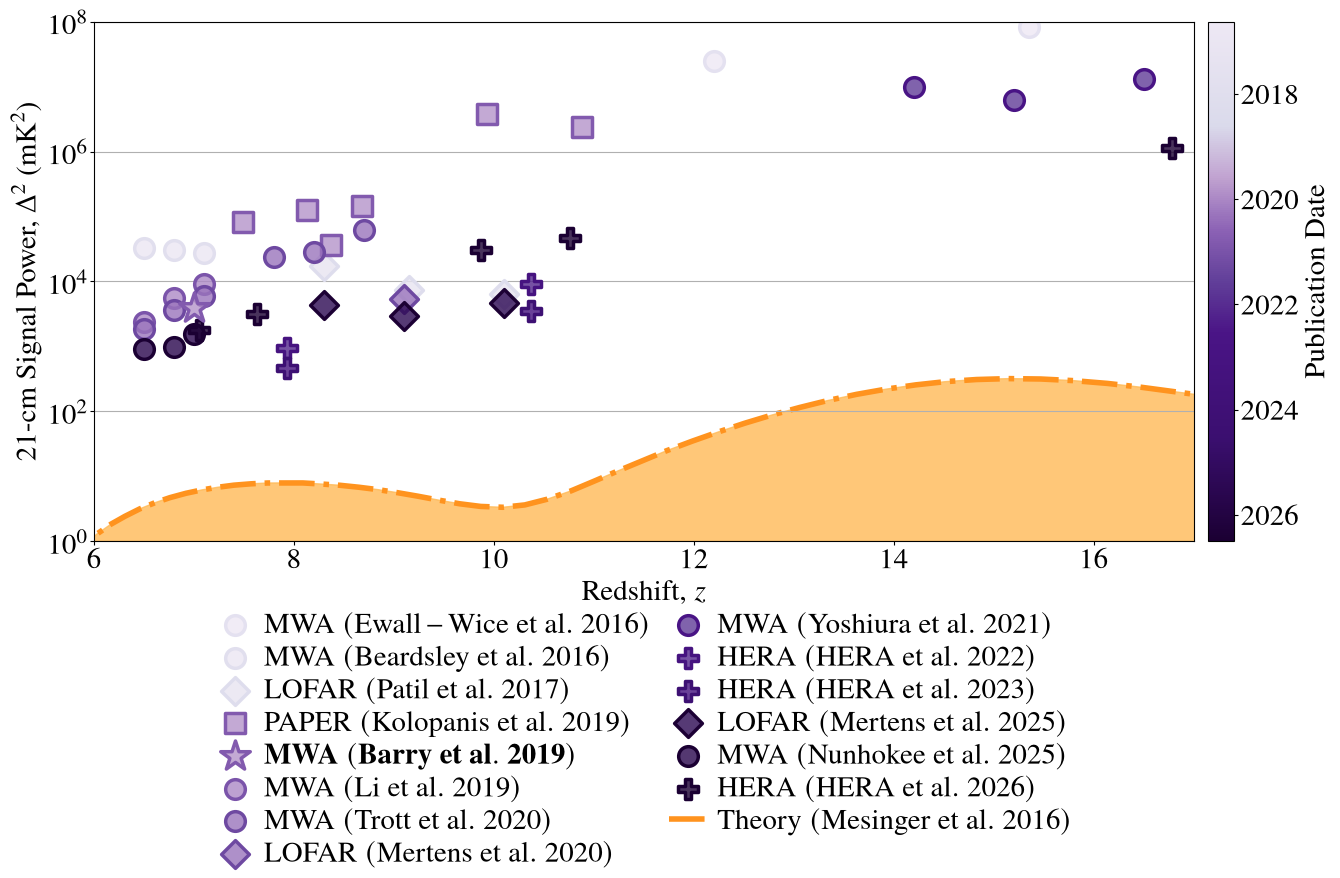

In [66]:


fig = plot_vs_z(color_by="year",k_labels=None,
    out="/Users/nicholebarry/software/eor_limits/Figure_3_draft.svg",
    data_dir="/Users/nicholebarry/OneDrive - UNSW/data/eor_limits/data/",
    theory_dir="/Users/nicholebarry/OneDrive - UNSW/data/eor_limits/theory",
    publication=True, delta_squared_range=[10**(0),10**(8)], z_range=[6,17], fontsize=21,
    bold_limits="Barry2019", colormap=cb_spec, fig_width=14, legend_ncols=2, fig_ratio=0.65,
    limits=["Beardsley2016.yaml","Ewall-Wice2016.yaml","Patil2017.yaml",
        "Li2019.yaml","Eastwood2019.yaml","Kolopanis2019.yaml","Gehlot2020.yaml","Trott2020.yaml","Mertens2020.yaml",
        "Garsden2021.yaml","Yoshiura2021.yaml","Pal2021.yaml","HERA2022.yaml",
        "HERA2023.yaml",
        "Mertens2025.yaml",
        "Nunhokee2025.yaml","HERA2026.yaml","Barry2019.yaml"
        ],
    theories=["Mesinger2016Faint"],base_theory_style={"linestyle": "-."},
    limit_styles={
        "Barry2019": {
            "marker": "*",
            "s": 500,
        },
    },
    theory_styles={
        "Mesinger2016Faint": {
            "color": "#FF931E",
            "shade_alpha": 0.8,
            "linewidth": 4,
            "shade_color": "#FFBA56",
        },
    }
                
)
